# Deep Learning: Generative Models Hands-On (VAE, GAN, Diffusion, Flows)

> **Who is this for:** a beginner who has read the theory notebook [`06_generative_models.ipynb`](06_generative_models.ipynb) and wants to *train* every major family of generative model on a laptop CPU, and BS/MS AI students revising the ELBO, GAN objectives, DDPM and normalizing flows.
>
> **What you will learn**
> - **Autoencoder vs VAE** on 8×8 digits: the two ELBO terms tracked separately, latent-space maps and interpolation, and the **β-VAE** trade-off
> - **GANs** on a 2-D ring of Gaussians: saturating vs non-saturating loss, **mode coverage**, **WGAN-GP**; then a small **DCGAN** on digits
> - **DDPM from scratch**: noise schedule, forward process, ε-prediction network and sampling loop, first on 2-D data, then on digits; **DDIM** fast sampling; **classifier-free guidance**
> - A **normalizing flow** (RealNVP coupling layers) with an **exact log-likelihood**
> - **Evaluating** generative models: likelihood, precision/recall for distributions, a nearest-neighbour **memorisation** check, and an **FID-style** score with a small feature network
> - A comparison table: VAE vs GAN vs flow vs diffusion
>
> **Prerequisites:** [`06_generative_models.ipynb`](06_generative_models.ipynb) (formulas), [`18_neural_networks_from_scratch_numpy.ipynb`](18_neural_networks_from_scratch_numpy.ipynb) (training mechanics), [`00_start_here_pytorch_from_zero.ipynb`](00_start_here_pytorch_from_zero.ipynb), and [`14_Mathematics/03_probability.ipynb`](../14_Mathematics/03_probability.ipynb) / [`14_Mathematics/05_information_theory.ipynb`](../14_Mathematics/05_information_theory.ipynb) (Gaussians, KL divergence).
>
> **Time needed:** about 4 hours.
>
> **Runs on:** CPU, no API key, no downloads (scikit-learn's built-in 8×8 digits and synthetic 2-D data). Every model is tiny; the whole notebook runs in a few minutes.
>
> **Optional track:** this notebook is part of the **university-level fundamentals track**. We recommend it for BS/MS AI students and for interview prep. It is the hands-on companion to [`06_generative_models.ipynb`](06_generative_models.ipynb) and [`06_Computer_Vision/06_image_generation.ipynb`](../06_Computer_Vision/06_image_generation.ipynb).

## Explained simply

A **generative model** learns what a kind of data "looks like" so well that it can make up **new** examples: new faces, new sentences, new handwritten digits. A classifier answers "is this a 3 or an 8?"; a generative model answers "draw me a 3". There are four big families. A **VAE** learns to compress each image into a few numbers and back, while keeping those numbers tidy so that random numbers also decode into sensible images. A **GAN** is a forger and a detective in a contest: the forger (generator) improves until the detective (discriminator) can no longer tell fakes from real. A **diffusion model** learns to remove noise step by step; start from pure static and "un-noise" your way to a picture. A **normalizing flow** is a reversible warping of a simple cloud of points into the shape of the data, which lets it compute exactly how likely any example is.

Everyday pictures: **a police sketch artist** builds faces from a few descriptive numbers (a VAE's latent code). **Restoring an old, scratched photo** a little at a time is what a diffusion model does, except it starts from pure noise. **Stretching and folding dough** without tearing it is a normalizing flow.

**A tiny example.** Suppose every "image" is a single number, and real data are heights of adults around 170 cm. A generative model that has learned "about 170, give or take 10" can invent new heights like 164 or 178. A model that only ever outputs 170 is precise but has **no diversity** (a GAN failure called *mode collapse*); a model that outputs anything from 0 to 300 has diversity but **no quality**. Section 6 measures exactly these two things, precision and recall, for our models.

**In one line**

| Concept | Simple meaning | Where you see it in real life / AI |
|---|---|---|
| VAE | compress to a few tidy numbers, then decode | the "autoencoder" that compresses images inside Stable Diffusion (latent diffusion) |
| GAN | forger vs detective game | StyleGAN faces, super-resolution, fast image-to-image tools |
| Diffusion | learn to remove noise, then generate from pure noise | Stable Diffusion, DALL·E 3, Imagen, video and audio generators |

## Contents

1. Setup and data
2. Autoencoder vs variational autoencoder (VAE), β-VAE
3. GANs: losses, mode coverage on a ring of Gaussians, WGAN-GP, a small DCGAN
4. Diffusion: DDPM from scratch (2-D, then digits), DDIM, classifier-free guidance
5. A normalizing flow (RealNVP) with exact likelihood
6. Evaluating generative models
7. Comparison table
8. How this connects to modern AI
9. Recap, practice problems, further reading

## 1. Setup and data

> 💬 **In plain English:** we load PyTorch and the 1,797 tiny 8×8 handwritten digits that ship with scikit-learn, and write a helper that draws a grid of images.

train torch.Size([1437, 64]) test torch.Size([360, 64])


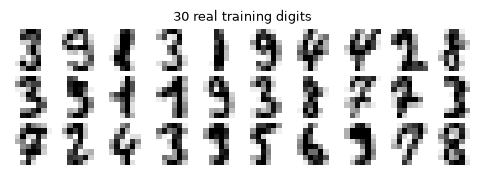

In [1]:
import math, time, random                               # standard helpers
import numpy as np                                      # arrays
import pandas as pd                                     # result tables
import matplotlib.pyplot as plt                         # plots
import torch                                            # tensors + autograd
import torch.nn as nn                                   # layers
import torch.nn.functional as F                         # losses and activations
from sklearn.datasets import load_digits, make_moons    # built-in data, no download
from sklearn.model_selection import train_test_split

torch.set_num_threads(2)                                # tiny models: 2 threads are plenty
SEED = 0
def seed_all(seed=SEED):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
seed_all()
pd.set_option("display.precision", 3)

digits = load_digits()
X_all = digits.data.astype(np.float32) / 16.0           # pixel values in [0, 1]
Xtr, Xte, ytr, yte = train_test_split(X_all, digits.target, test_size=0.2, random_state=SEED, stratify=digits.target)
Xtr_t, Xte_t = torch.tensor(Xtr), torch.tensor(Xte)
ytr_t, yte_t = torch.tensor(ytr), torch.tensor(yte)
print("train", Xtr_t.shape, "test", Xte_t.shape)

def show_grid(imgs, ncol=10, title=None, ax=None, size=0.6):
    # imgs: (N, 64) array/tensor with values in [0, 1]; draws them as a grid of 8x8 images.
    imgs = torch.as_tensor(imgs).detach().clamp(0, 1).reshape(-1, 8, 8).numpy()
    n = len(imgs); nrow = int(math.ceil(n / ncol))
    canvas = np.zeros((nrow * 9 - 1, ncol * 9 - 1))              # 0 = white background with gray_r
    for k, im in enumerate(imgs):
        r, c = divmod(k, ncol); canvas[r * 9:r * 9 + 8, c * 9:c * 9 + 8] = im
    if ax is None:
        _, ax = plt.subplots(figsize=(ncol * size, nrow * size))
    ax.imshow(canvas, cmap="gray_r", vmin=0, vmax=1); ax.axis("off")
    if title: ax.set_title(title, fontsize=9)
    return ax

show_grid(Xtr[:30], title="30 real training digits"); plt.show()

## 2. Autoencoder vs variational autoencoder

> 💬 **In plain English:** an autoencoder squeezes an image into a short code and rebuilds it. A VAE does the same, but forces the codes to fill a neat cloud around zero, so that *any* point in that cloud decodes into a believable image.

**Autoencoder (AE).** Encoder $z = e(x)$, decoder $\hat x = d(z)$, trained to minimise a reconstruction loss. Nothing controls *where* codes land, so a random $z$ often decodes to garbage: an AE compresses, but it is not a proper generative model.

**VAE** (Kingma & Welling, 2014). A probabilistic encoder $q_\phi(z\mid x) = \mathcal N(\mu_\phi(x), \operatorname{diag}\sigma^2_\phi(x))$, a prior $p(z)=\mathcal N(0,I)$, and a decoder $p_\theta(x\mid z)$. Training maximises the **evidence lower bound**

$$\log p_\theta(x) \;\ge\; \text{ELBO}(x) = \underbrace{\mathbb E_{q_\phi(z\mid x)}[\log p_\theta(x\mid z)]}_{\text{reconstruction}} \;-\; \underbrace{\mathrm{KL}\big(q_\phi(z\mid x)\,\Vert\, p(z)\big)}_{\text{keeps codes near the prior}}.$$

For a diagonal Gaussian the KL term has a closed form: $\mathrm{KL} = \tfrac12\sum_j(\mu_j^2 + \sigma_j^2 - 1 - \log\sigma_j^2)$.

**Reparameterisation trick.** Sampling $z\sim\mathcal N(\mu,\sigma^2)$ is not differentiable in $\mu,\sigma$; writing $z = \mu + \sigma\odot\varepsilon$ with $\varepsilon\sim\mathcal N(0,I)$ moves the randomness into $\varepsilon$, so gradients flow into the encoder.

Our decoder outputs one logit per pixel and we use binary cross-entropy against the pixel intensity in $[0,1]$ (the usual choice for MNIST-like data). We minimise the **negative ELBO** = recon + $\beta\cdot$KL, reported per image in nats.

| Hand example (1-D latent) | Value |
|---|---|
| encoder output $\mu = 1,\ \sigma = 0.5$ | |
| $\mathrm{KL} = \tfrac12(1 + 0.25 - 1 - \ln 0.25)$ | $\tfrac12(0.25 + 1.386) = 0.818$ nats |
| with $\varepsilon = -0.4$: $z = 1 + 0.5(-0.4)$ | $0.8$ |

KL(N(1, 0.5^2) || N(0,1)) = 0.818


trained AE and VAE in 5.1s
VAE test: recon 22.5 + KL 2.35 = negative ELBO 24.9 nats per image
AE  test: recon 21.3 nats per image (no KL term, no likelihood bound)


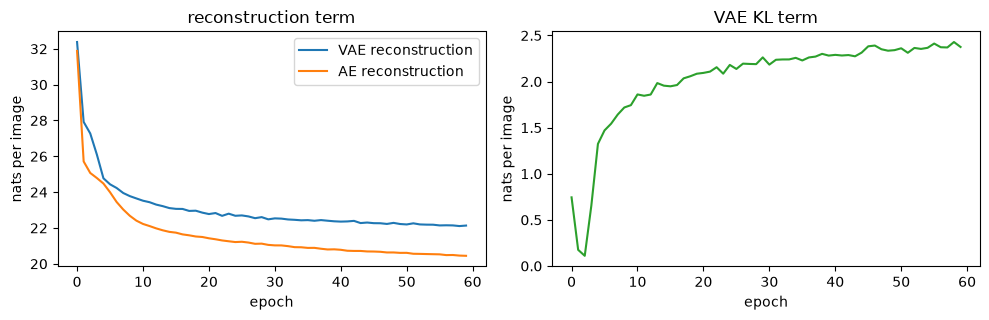

In [2]:
class AE(nn.Module):
    def __init__(self, z_dim=2, h=256):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, z_dim))
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, 64))   # pixel logits

    def forward(self, x):
        z = self.enc(x)
        return self.dec(z), z


class VAE(nn.Module):
    def __init__(self, z_dim=2, h=256):
        super().__init__()
        self.enc = nn.Sequential(nn.Linear(64, h), nn.ReLU(), nn.Linear(h, 2 * z_dim))  # -> [mu, log sigma^2]
        self.dec = nn.Sequential(nn.Linear(z_dim, h), nn.ReLU(), nn.Linear(h, 64))
        self.z_dim = z_dim

    def encode(self, x):
        mu, logvar = self.enc(x).chunk(2, dim=-1)
        return mu, logvar

    def forward(self, x):
        mu, logvar = self.encode(x)
        z = mu + torch.exp(0.5 * logvar) * torch.randn_like(mu)        # reparameterisation trick
        return self.dec(z), mu, logvar


def vae_terms(logits, x, mu, logvar):
    recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x)   # -E[log p(x|z)] per image
    kl = 0.5 * (mu ** 2 + logvar.exp() - 1 - logvar).sum() / len(x)                   # closed-form KL per image
    return recon, kl

# Check the hand example with torch.distributions
q, p = torch.distributions.Normal(1.0, 0.5), torch.distributions.Normal(0.0, 1.0)
print("KL(N(1, 0.5^2) || N(0,1)) =", round(torch.distributions.kl_divergence(q, p).item(), 3))


def train_autoencoder(kind="vae", z_dim=2, beta=1.0, epochs=60, seed=SEED):
    seed_all(seed)
    model = VAE(z_dim) if kind == "vae" else AE(z_dim)
    opt = torch.optim.Adam(model.parameters(), lr=2e-3)
    hist = []
    for epoch in range(epochs):
        perm = torch.randperm(len(Xtr_t)); sums = np.zeros(2)
        for i in range(0, len(perm), 64):
            x = Xtr_t[perm[i:i + 64]]
            if kind == "vae":
                logits, mu, logvar = model(x)
                recon, kl = vae_terms(logits, x, mu, logvar)
            else:
                logits, _ = model(x)
                recon = F.binary_cross_entropy_with_logits(logits, x, reduction="sum") / len(x); kl = torch.tensor(0.0)
            loss = recon + beta * kl
            opt.zero_grad(); loss.backward(); opt.step()
            sums += np.array([recon.item(), kl.item()]) * len(x)
        hist.append(sums / len(Xtr_t))
    return model, np.array(hist)

t0 = time.perf_counter()
ae, ae_hist = train_autoencoder("ae")
vae, vae_hist = train_autoencoder("vae")
print(f"trained AE and VAE in {time.perf_counter() - t0:.1f}s")

@torch.no_grad()
def neg_elbo(model, X, n_samples=10):
    out = []
    for _ in range(n_samples):
        logits, mu, logvar = model(X); r, k = vae_terms(logits, X, mu, logvar); out.append([r.item(), k.item()])
    r, k = np.mean(out, 0)
    return r, k, r + k

r, k, ne = neg_elbo(vae, Xte_t)
print(f"VAE test: recon {r:.1f} + KL {k:.2f} = negative ELBO {ne:.1f} nats per image")
with torch.no_grad():
    ae_recon = F.binary_cross_entropy_with_logits(ae(Xte_t)[0], Xte_t, reduction="sum").item() / len(Xte_t)
print(f"AE  test: recon {ae_recon:.1f} nats per image (no KL term, no likelihood bound)")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.3))
ax[0].plot(vae_hist[:, 0], label="VAE reconstruction"); ax[0].plot(ae_hist[:, 0], label="AE reconstruction")
ax[0].set_ylabel("nats per image"); ax[0].set_title("reconstruction term"); ax[0].legend()
ax[1].plot(vae_hist[:, 1], color="tab:green"); ax[1].set_title("VAE KL term"); ax[1].set_ylabel("nats per image")
for a in ax: a.set_xlabel("epoch")
plt.tight_layout(); plt.show()

**What just happened?** We tracked the two ELBO terms separately. The AE reconstructs better (lower reconstruction loss) because it is free to put codes anywhere; the VAE pays a KL "rent" of a few nats per image to keep its codes close to $\mathcal N(0, I)$. Note that binary cross-entropy against grey-level targets can never reach 0 (the targets themselves have entropy), so only differences between the numbers are meaningful. The VAE's negative ELBO is an **upper bound on $-\log p(x)$**, a genuine (if loose) likelihood number; the AE has none.

Now look at what that KL rent buys.

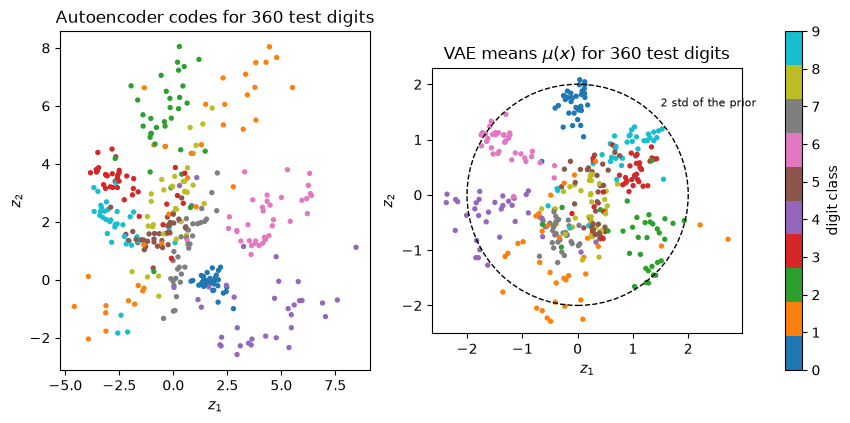

spread of codes (std per dimension):  AE [2.57 2.24]   VAE [0.94 0.93]


In [3]:
with torch.no_grad():
    z_ae = ae.enc(Xte_t).numpy()
    z_vae = vae.encode(Xte_t)[0].numpy()

fig, ax = plt.subplots(1, 2, figsize=(11, 4.4))
for a, z, name in [(ax[0], z_ae, "Autoencoder codes"), (ax[1], z_vae, "VAE means $\\mu(x)$")]:
    sc = a.scatter(z[:, 0], z[:, 1], c=yte, cmap="tab10", s=8)
    a.set_title(f"{name} for 360 test digits"); a.set_xlabel("$z_1$"); a.set_ylabel("$z_2$")
ax[1].set_aspect("equal"); ax[1].add_patch(plt.Circle((0, 0), 2, fill=False, ls="--", color="k")); ax[1].text(1.5, 1.6, "2 std of the prior", fontsize=8)
plt.colorbar(sc, ax=ax, label="digit class"); plt.show()
print("spread of codes (std per dimension):  AE", z_ae.std(0).round(2), "  VAE", z_vae.std(0).round(2))

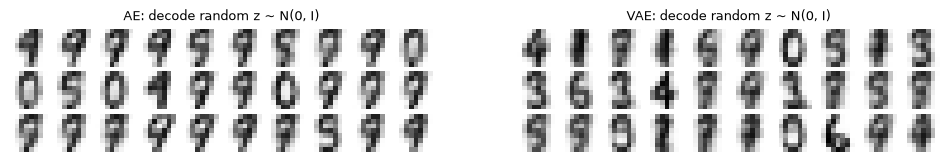

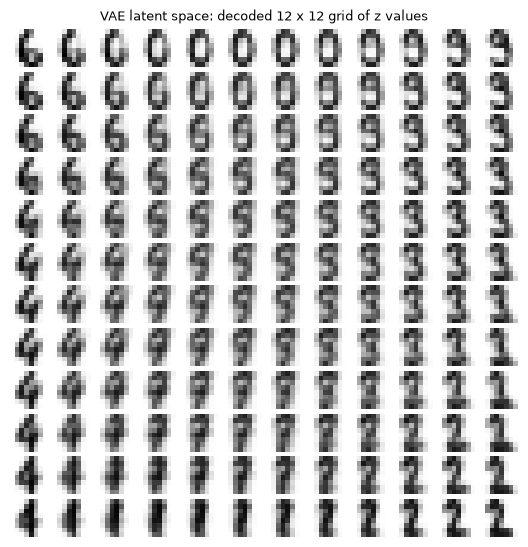

In [4]:
seed_all(1)
z = torch.randn(30, 2)                                       # random points from the prior N(0, I)
with torch.no_grad():
    fake_ae, fake_vae = torch.sigmoid(ae.dec(z)), torch.sigmoid(vae.dec(z))
fig, ax = plt.subplots(1, 2, figsize=(12, 2.4))
show_grid(fake_ae, title="AE: decode random z ~ N(0, I)", ax=ax[0])
show_grid(fake_vae, title="VAE: decode random z ~ N(0, I)", ax=ax[1]); plt.show()

# The VAE's 2-D latent space as a map: decode a 12 x 12 grid of points (Normal quantiles span the prior)
from scipy.stats import norm
q = norm.ppf(np.linspace(0.04, 0.96, 12)).astype(np.float32)
grid = torch.tensor([[a, b] for b in q[::-1] for a in q])
with torch.no_grad():
    manifold = torch.sigmoid(vae.dec(grid))
show_grid(manifold, ncol=12, title="VAE latent space: decoded 12 x 12 grid of z values", size=0.55); plt.show()

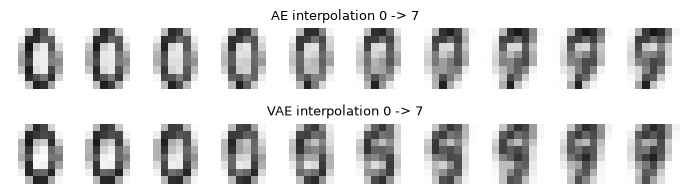

In [5]:
# Latent interpolation between two test digits: decode points on the straight line between their codes
i0, i1 = int(np.where(yte == 0)[0][0]), int(np.where(yte == 7)[0][0])
alphas = torch.linspace(0, 1, 10)[:, None]
with torch.no_grad():
    za, zb = ae.enc(Xte_t[[i0, i1]])
    path_ae = torch.sigmoid(ae.dec((1 - alphas) * za + alphas * zb))
    ma, mb = vae.encode(Xte_t[[i0, i1]])[0]
    path_vae = torch.sigmoid(vae.dec((1 - alphas) * ma + alphas * mb))
fig, ax = plt.subplots(2, 1, figsize=(7, 2.2))
show_grid(path_ae, title="AE interpolation 0 -> 7", ax=ax[0]); show_grid(path_vae, title="VAE interpolation 0 -> 7", ax=ax[1])
plt.tight_layout(); plt.show()

**What just happened?**

- **Latent maps.** The AE's codes spread wherever is convenient (their scale is arbitrary), so the prior $\mathcal N(0,I)$ covers only a corner of them, and random codes decode into the same few shapes over and over. The VAE's codes are pulled into the unit-Gaussian region, so random draws from the prior decode into digit-like images, and the decoded grid is a smooth "map" in which neighbouring points are similar digits.
- **Interpolation.** Walking along a straight line between the codes of a 0 and a 7 passes through other digit-like shapes for the VAE, because every region near the prior is trained to decode to something plausible.
- VAE samples are **blurry**: the Gaussian-style likelihood averages over the plausible images for each code. Sharper samples are the main selling point of GANs and diffusion models.

### 2.1 β-VAE: trading reconstruction for a tidier latent space

> 💬 **In plain English:** β is a knob for how much the model is charged for using its code; a higher charge gives simpler, smoother codes but blurrier reconstructions.

The **β-VAE** (Higgins et al., 2017) minimises recon $+\ \beta\cdot$KL. $\beta>1$ squeezes information out of $z$ (smoother, often more disentangled latents, blurrier images); $\beta<1$ keeps more detail but leaves "holes" in the latent space where prior samples decode poorly. Only $\beta=1$ gives a true ELBO. We use an 8-dimensional latent here.

           test recon (nats)  test KL (nats)  recon + KL  \
beta=0.25             18.046           9.242      27.287   
beta=1.0              21.298           3.268      24.566   
beta=4.0              27.251           0.007      27.258   

           active latent dims (of 8)  
beta=0.25                        8.0  
beta=1.0                         6.0  
beta=4.0                         0.0  


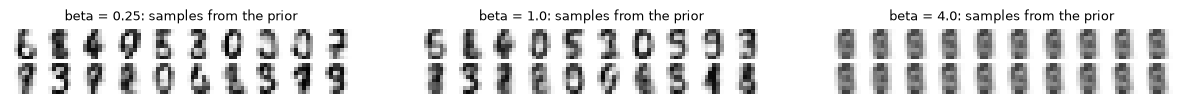

In [6]:
beta_rows, beta_models = {}, {}
for beta in [0.25, 1.0, 4.0]:
    m, h = train_autoencoder("vae", z_dim=8, beta=beta, epochs=40)
    r, k, _ = neg_elbo(m, Xte_t)
    with torch.no_grad():
        active = (m.encode(Xte_t)[0].var(0) > 0.01).sum().item()      # latent dims the encoder actually uses
    beta_rows[f"beta={beta}"] = {"test recon (nats)": r, "test KL (nats)": k, "recon + KL": r + k, "active latent dims (of 8)": active}
    beta_models[beta] = m
print(pd.DataFrame(beta_rows).T)

fig, ax = plt.subplots(1, 3, figsize=(15, 1.9))
seed_all(2); z = torch.randn(20, 8)
for a, (beta, m) in zip(ax, beta_models.items()):
    with torch.no_grad():
        show_grid(torch.sigmoid(m.dec(z)), title=f"beta = {beta}: samples from the prior", ax=a)
plt.show()

**What just happened?** As β grows, the KL term shrinks and reconstruction gets worse: the model stores less information in $z$. At $\beta = 1$ the encoder already leaves 2 of the 8 dimensions unused; at $\beta = 4$ it switches off **all** of them (KL ≈ 0): the posterior equals the prior, the decoder ignores $z$ and every sample is the same average blob. This is **posterior collapse**, the extreme end of the trade-off. With $\beta = 0.25$ all 8 dimensions are used and reconstructions are sharpest, but the KL is large. $\beta = 1$ has the best recon + KL total, as it should: it is the only setting that optimises the actual bound on $\log p(x)$.

> ⚠️ **Common mistake:** averaging the reconstruction loss over pixels (`reduction="mean"`) but summing the KL over latent dimensions. That silently sets $\beta_{effective} = 64\beta$ for 64 pixels, and the VAE collapses to the mean image. Keep both terms per *image*.

## 3. Generative adversarial networks (GANs)

> 💬 **In plain English:** the generator turns random noise into fake samples; the discriminator tries to tell fakes from real data; each one's mistakes are the other one's training signal.

**Definition** (Goodfellow et al., 2014). Generator $G(z)$, discriminator $D(x)\in(0,1)$, value function

$$\min_G\max_D\ V(D,G) = \mathbb E_{x\sim p_{data}}[\log D(x)] + \mathbb E_{z\sim p(z)}[\log(1-D(G(z)))].$$

For a fixed $G$ the optimal discriminator is $D^*(x) = p_{data}(x)/(p_{data}(x)+p_g(x))$, and then $V = 2\,\mathrm{JS}(p_{data}\Vert p_g) - \log 4$: the generator minimises a Jensen-Shannon divergence. GANs have **no encoder and no likelihood**; they are judged only by their samples.

**Saturating vs non-saturating generator loss.** Early in training $D$ easily rejects fakes, $D(G(z))\approx 0$, and $\log(1-D(G(z)))$ is flat there: the generator gets almost no gradient. The **non-saturating** loss $-\log D(G(z))$ has the same fixed point but a strong gradient exactly when the generator is bad. With $D = \sigma(\ell)$ (logit $\ell$):

| Generator loss | gradient w.r.t. the logit $\ell$ | at $D(G(z)) = 0.01$ |
|---|---|---|
| saturating: minimise $\log(1-\sigma(\ell))$ | $-\sigma(\ell) = -D$ | $-0.01$ (vanishes) |
| non-saturating: minimise $-\log\sigma(\ell)$ | $-(1-\sigma(\ell)) = -(1-D)$ | $-0.99$ (strong) |

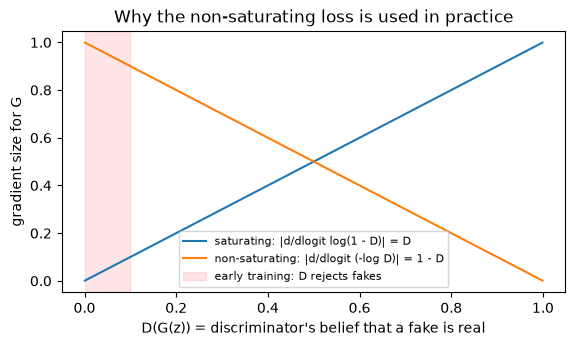

In [7]:
D_vals = np.linspace(0.001, 0.999, 300)
plt.figure(figsize=(6.5, 3.4))
plt.plot(D_vals, D_vals, label="saturating: |d/dlogit log(1 - D)| = D")
plt.plot(D_vals, 1 - D_vals, label="non-saturating: |d/dlogit (-log D)| = 1 - D")
plt.axvspan(0, 0.1, color="red", alpha=0.1, label="early training: D rejects fakes")
plt.xlabel("D(G(z)) = discriminator's belief that a fake is real"); plt.ylabel("gradient size for G")
plt.title("Why the non-saturating loss is used in practice"); plt.legend(fontsize=8); plt.show()

### 3.1 A ring of 8 Gaussians: watching mode coverage

> 💬 **In plain English:** the real data are 8 small blobs on a circle. A good generator must produce points in *all 8* blobs; producing only a few of them is **mode collapse**.

Data: 8 Gaussians with standard deviation 0.05 on a circle of radius 2. Generator and discriminator are 2-hidden-layer MLPs. We count a mode as **covered** if at least 1% of 2,000 samples fall within 4 standard deviations of its centre, and report the share of **high-quality** samples (within 4 std of *some* centre).

**WGAN-GP** (Arjovsky et al., 2017; Gulrajani et al., 2017) replaces the discriminator by a **critic** $f$ (no sigmoid) that estimates the Wasserstein-1 distance $\mathbb E_{data}[f(x)] - \mathbb E_{g}[f(G(z))]$, which requires $f$ to be 1-Lipschitz. The **gradient penalty** $\lambda\,\mathbb E_{\hat x}[(\lVert\nabla_{\hat x} f(\hat x)\rVert - 1)^2]$ on random interpolates $\hat x$ between real and fake points enforces this softly ($\lambda = 10$, 5 critic steps per generator step, Adam with $\beta_1 = 0$).

In [8]:
K_MODES, RADIUS, STD = 8, 2.0, 0.05
centers = torch.tensor([[RADIUS * math.cos(2 * math.pi * k / K_MODES), RADIUS * math.sin(2 * math.pi * k / K_MODES)]
                        for k in range(K_MODES)])

def sample_ring(n):
    k = torch.randint(0, K_MODES, (n,))
    return centers[k] + STD * torch.randn(n, 2)

def mlp(n_in, n_out, h=128):
    return nn.Sequential(nn.Linear(n_in, h), nn.ReLU(), nn.Linear(h, h), nn.ReLU(), nn.Linear(h, n_out))

def mode_stats(x):
    d = torch.cdist(x, centers).min(1)
    good = d.values < 4 * STD                                         # close to some centre
    counts = torch.bincount(d.indices[good], minlength=K_MODES)
    return int((counts >= 0.01 * len(x)).sum()), good.float().mean().item()

def train_gan(kind, steps=1500, lr=1e-3, seed=SEED, n_snap=3):
    seed_all(seed)
    G, D = mlp(2, 2), mlp(2, 1)
    betas = (0.0, 0.9) if kind == "wgan-gp" else (0.5, 0.999)
    opt_G = torch.optim.Adam(G.parameters(), lr=lr, betas=betas)
    opt_D = torch.optim.Adam(D.parameters(), lr=lr, betas=betas)
    ones, zeros = torch.ones(256, 1), torch.zeros(256, 1)
    snaps = {}
    for it in range(1, steps + 1):
        for _ in range(5 if kind == "wgan-gp" else 1):                # critic / discriminator updates
            real, fake = sample_ring(256), G(torch.randn(256, 2)).detach()
            if kind == "wgan-gp":
                eps = torch.rand(256, 1)
                x_hat = (eps * real + (1 - eps) * fake).requires_grad_(True)
                grad = torch.autograd.grad(D(x_hat).sum(), x_hat, create_graph=True)[0]
                loss_D = D(fake).mean() - D(real).mean() + 10 * ((grad.norm(dim=1) - 1) ** 2).mean()
            else:
                loss_D = F.binary_cross_entropy_with_logits(D(real), ones) + F.binary_cross_entropy_with_logits(D(fake), zeros)
            opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        logit = D(G(torch.randn(256, 2)))
        if kind == "saturating":
            loss_G = -F.binary_cross_entropy_with_logits(logit, zeros)      # = minimise log(1 - D(G(z)))
        elif kind == "non-saturating":
            loss_G = F.binary_cross_entropy_with_logits(logit, ones)        # = minimise -log D(G(z))
        else:
            loss_G = -logit.mean()                                           # WGAN: maximise critic score
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()
        if it % (steps // n_snap) == 0:
            with torch.no_grad():
                snaps[it] = G(torch.randn(2000, 2))
    return G, D, snaps

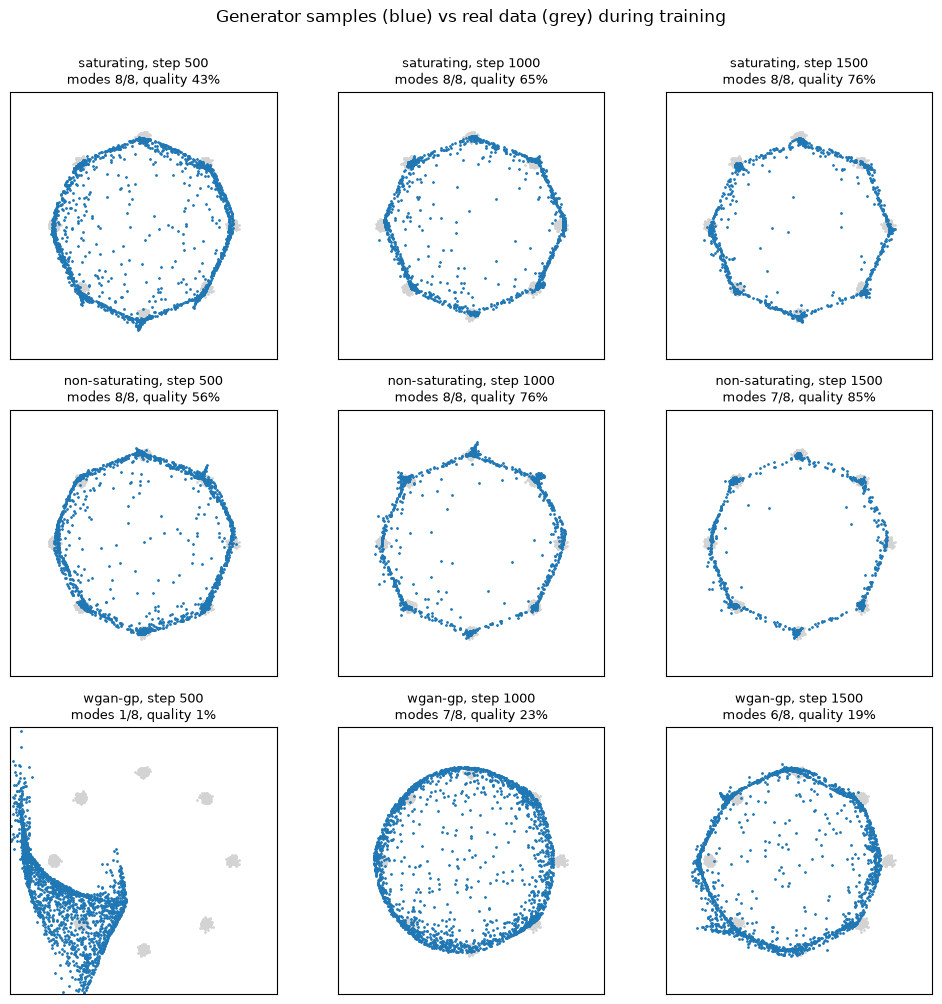

               modes covered (of 8) high-quality samples  \
saturating                        8                 0.76   
non-saturating                    7                 0.85   
wgan-gp                           6                0.188   

               modes covered over snapshots train time (s)  
saturating                        [8, 8, 8]          7.647  
non-saturating                    [8, 8, 7]          7.694  
wgan-gp                           [1, 7, 6]         35.882  


In [9]:
gan_runs, gan_times = {}, {}
for kind in ["saturating", "non-saturating", "wgan-gp"]:
    t0 = time.perf_counter(); gan_runs[kind] = train_gan(kind); gan_times[kind] = time.perf_counter() - t0

real_pts = sample_ring(2000)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for r, (kind, (G, D, snaps)) in enumerate(gan_runs.items()):
    for c, (it, pts) in enumerate(snaps.items()):
        a = axes[r, c]
        a.scatter(real_pts[:, 0], real_pts[:, 1], s=1, c="lightgray")
        a.scatter(pts[:, 0], pts[:, 1], s=1, c="tab:blue")
        m, q = mode_stats(pts)
        a.set_title(f"{kind}, step {it}\nmodes {m}/8, quality {q:.0%}", fontsize=9)
        a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_aspect("equal"); a.set_xticks([]); a.set_yticks([])
plt.suptitle("Generator samples (blue) vs real data (grey) during training", y=1.0); plt.tight_layout(); plt.show()

rows = {}
for kind, (G, D, snaps) in gan_runs.items():
    m, q = mode_stats(list(snaps.values())[-1])
    rows[kind] = {"modes covered (of 8)": m, "high-quality samples": q,
                  "modes covered over snapshots": [mode_stats(s)[0] for s in snaps.values()], "train time (s)": gan_times[kind]}
print(pd.DataFrame(rows).T)

**What just happened?** In this small 2-D problem all three objectives learn the ring. The saturating loss works here (our discriminator never becomes confident enough early on to starve the generator), but its sample quality lags behind: 76% of samples land on a mode after 1,500 steps, vs 85% for the non-saturating loss. Notice the thin **bridges** of samples between neighbouring blobs: the generator is a continuous map from a single Gaussian blob, so it cannot jump between separate modes without passing through the gaps; training can only make the bridges thinner. Mode counts also fluctuate between snapshots (at the last snapshot one of the non-saturating GAN's modes fell just below the 1% threshold): GAN training chases a moving target. WGAN-GP improves more slowly per generator step here and costs about 5 times more compute per step (5 critic updates, each with a second backward pass for the gradient penalty); its advantages are stability and a critic value that tracks sample quality on harder problems, not speed on toy data.

> 🎓 **Exam / interview tip:** "Why is GAN training unstable?" It is a two-player game, not a minimisation: gradient descent on both players can cycle around the equilibrium instead of converging, and when the discriminator becomes too good the JS-divergence-based signal saturates. Remedies: non-saturating loss, Wasserstein loss with gradient penalty, spectral normalisation, a two-time-scale update rule (different learning rates), and keeping the discriminator from overpowering the generator.

### 3.2 Mode collapse, isolated

> 💬 **In plain English:** if the detective stops learning, the forger's best strategy is to make the *one* fake the detective likes most, over and over.

For a **fixed** discriminator, the generator's best response is to put all of its samples on the point(s) where $D$ is highest: complete mode collapse. Real training alternates, so the discriminator then learns to reject that point and the generator hops elsewhere ("mode hopping"); collapse in practice is this chase failing to settle. We take the trained non-saturating GAN, **freeze its discriminator**, and keep training only the generator.

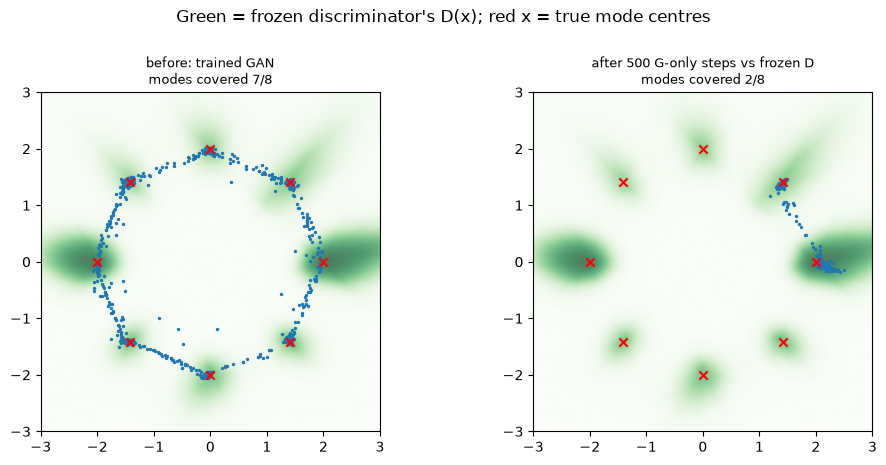

In [10]:
import copy
G_trained, D_trained, _ = gan_runs["non-saturating"]
G_free = copy.deepcopy(G_trained)
D_frozen = copy.deepcopy(D_trained).requires_grad_(False)          # the detective stops learning
opt_free = torch.optim.Adam(G_free.parameters(), lr=1e-2, betas=(0.5, 0.999))
seed_all(4)
for it in range(500):
    loss = F.binary_cross_entropy_with_logits(D_frozen(G_free(torch.randn(256, 2))), torch.ones(256, 1))
    opt_free.zero_grad(); loss.backward(); opt_free.step()

g1, g2 = torch.meshgrid(torch.linspace(-3, 3, 200), torch.linspace(-3, 3, 200), indexing="xy")
with torch.no_grad():
    d_map = torch.sigmoid(D_frozen(torch.stack([g1.ravel(), g2.ravel()], 1))).view(200, 200)
    before, after = G_trained(torch.randn(2000, 2)), G_free(torch.randn(2000, 2))
fig, ax = plt.subplots(1, 2, figsize=(10, 4.6))
for a, pts, title in [(ax[0], before, "before: trained GAN"), (ax[1], after, "after 500 G-only steps vs frozen D")]:
    a.imshow(d_map.numpy(), origin="lower", extent=[-3, 3, -3, 3], cmap="Greens", alpha=0.7)
    a.scatter(pts[:, 0], pts[:, 1], s=2, c="tab:blue"); a.scatter(centers[:, 0], centers[:, 1], marker="x", c="red")
    m, q = mode_stats(pts); a.set_title(f"{title}\nmodes covered {m}/8", fontsize=9); a.set_xlim(-3, 3); a.set_ylim(-3, 3)
plt.suptitle("Green = frozen discriminator's D(x); red x = true mode centres", y=1.0); plt.tight_layout(); plt.show()

**What just happened?** Against a frozen discriminator, the generator abandons most of the ring and piles its samples onto the couple of regions where $D$ is highest (the darkest green): the mode count drops sharply while the share of samples that sit on *some* mode stays high. Every individual sample still looks fine, which is exactly why mode collapse is easy to miss by eye: you have to measure **coverage** (recall), not just quality.

### 3.3 A small DCGAN on 8×8 digits

> 💬 **In plain English:** the same forger-vs-detective game, but the forger paints with *transposed convolutions* (which grow an image) and the detective looks with ordinary convolutions.

**DCGAN** guidelines (Radford et al., 2016): strided (transposed) convolutions instead of pooling, BatchNorm in the generator, ReLU in the generator and LeakyReLU in the discriminator, tanh output, Adam with $\beta_1 = 0.5$.

| Generator | Shape | Discriminator | Shape |
|---|---|---|---|
| $z\in\mathbb R^{32}$ → Linear | 128×2×2 | image | 1×8×8 |
| ConvTranspose 4×4, stride 2 + BN + ReLU | 64×4×4 | Conv 4×4, stride 2 + LeakyReLU | 64×4×4 |
| ConvTranspose 4×4, stride 2 + tanh | 1×8×8 | Conv 4×4, stride 2 + LeakyReLU | 128×2×2 |
| | | Linear | 1 logit |

DCGAN trained in 35.1s


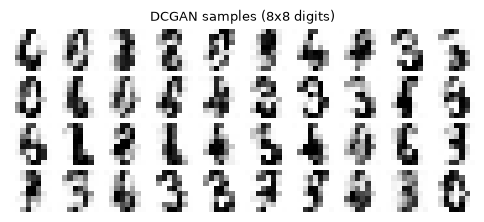

In [11]:
class DCGenerator(nn.Module):
    def __init__(self, z_dim=32):
        super().__init__()
        self.fc = nn.Sequential(nn.Linear(z_dim, 128 * 2 * 2), nn.BatchNorm1d(512), nn.ReLU())
        self.net = nn.Sequential(
            nn.ConvTranspose2d(128, 64, 4, stride=2, padding=1), nn.BatchNorm2d(64), nn.ReLU(),   # 2x2 -> 4x4
            nn.ConvTranspose2d(64, 1, 4, stride=2, padding=1), nn.Tanh())                        # 4x4 -> 8x8

    def forward(self, z):
        return self.net(self.fc(z).view(-1, 128, 2, 2))


class DCDiscriminator(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv2d(1, 64, 4, stride=2, padding=1), nn.LeakyReLU(0.2),       # 8x8 -> 4x4
            nn.Conv2d(64, 128, 4, stride=2, padding=1), nn.LeakyReLU(0.2),     # 4x4 -> 2x2
            nn.Flatten(), nn.Linear(128 * 2 * 2, 1))

    def forward(self, x):
        return self.net(x)


def train_dcgan(steps=1500, seed=SEED):
    seed_all(seed)
    G, D = DCGenerator(), DCDiscriminator()
    opt_G = torch.optim.Adam(G.parameters(), lr=2e-4 * 2, betas=(0.5, 0.999))
    opt_D = torch.optim.Adam(D.parameters(), lr=2e-4, betas=(0.5, 0.999))
    real_imgs = (Xtr_t * 2 - 1).view(-1, 1, 8, 8)                         # scale to [-1, 1] for tanh
    ones, zeros = torch.ones(64, 1), torch.zeros(64, 1)
    for it in range(steps):
        real = real_imgs[torch.randint(0, len(real_imgs), (64,))]
        fake = G(torch.randn(64, 32))
        loss_D = F.binary_cross_entropy_with_logits(D(real), ones) + F.binary_cross_entropy_with_logits(D(fake.detach()), zeros)
        opt_D.zero_grad(); loss_D.backward(); opt_D.step()
        loss_G = F.binary_cross_entropy_with_logits(D(fake), ones)              # non-saturating
        opt_G.zero_grad(); loss_G.backward(); opt_G.step()
    G.eval()
    return G

t0 = time.perf_counter()
dcgan_G = train_dcgan()
print(f"DCGAN trained in {time.perf_counter() - t0:.1f}s")
seed_all(3)
with torch.no_grad():
    dcgan_samples = (dcgan_G(torch.randn(1000, 32)).view(-1, 64) + 1) / 2   # back to [0, 1]
show_grid(dcgan_samples[:40], title="DCGAN samples (8x8 digits)"); plt.show()

**What just happened?** A two-layer convolutional generator learns to paint digit-like strokes from 32 random numbers in well under a minute. The samples are noticeably **sharper** than the VAE's (no pixel-averaging likelihood), but GAN samples can contain malformed digits, and there is no built-in way to know *how much* of the data distribution the generator covers; Section 6 measures that.

> ⚠️ **Common mistake:** judging a GAN by its losses. The discriminator and generator losses do not go down together like a normal training curve; they describe a two-player game. Monitor samples and a sample-quality metric (FID-style, precision/recall) instead.

## 4. Diffusion models (DDPM) from scratch

> 💬 **In plain English:** take a real example and add a little noise, many times, until only noise is left. Train a network to guess the noise that was added. To generate, start from pure noise and repeatedly subtract the network's noise guess.

**Forward (noising) process** (Ho, Jain & Abbeel, 2020), with a fixed schedule $\beta_1,\dots,\beta_T$:

$$q(x_t\mid x_{t-1}) = \mathcal N\big(\sqrt{1-\beta_t}\,x_{t-1},\ \beta_t I\big)\quad\Longrightarrow\quad x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\varepsilon,\ \ \varepsilon\sim\mathcal N(0,I),$$

where $\alpha_t = 1-\beta_t$ and $\bar\alpha_t = \prod_{s\le t}\alpha_s$. The closed form lets us jump to any $t$ in one step during training.

**Training objective** (the "simple" loss): pick a random $t$, noise $x_0$ to $x_t$, and regress the noise:

$$L_{simple} = \mathbb E_{t, x_0, \varepsilon}\big\lVert \varepsilon - \varepsilon_\theta(x_t, t)\big\rVert^2.$$

**Sampling (ancestral DDPM):** start at $x_T\sim\mathcal N(0,I)$ and for $t = T,\dots,1$:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\Big(x_t - \frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\varepsilon_\theta(x_t,t)\Big) + \sigma_t z,\qquad z\sim\mathcal N(0,I),\ \ \sigma_t^2 = \tilde\beta_t = \frac{1-\bar\alpha_{t-1}}{1-\bar\alpha_t}\beta_t,$$

with no noise added at the last step. The network gets $t$ through a **sinusoidal time embedding** (the same idea as Transformer positional encodings).

| Hand example (1-D, one step) | Value |
|---|---|
| $x_0 = 1.0$, $\bar\alpha_t = 0.64$, $\varepsilon = 0.5$ | |
| $x_t = 0.8(1.0) + 0.6(0.5)$ | $1.1$ |
| a perfect network predicts $\hat\varepsilon = 0.5$, so $\hat x_0 = (x_t - 0.6\hat\varepsilon)/0.8$ | $1.0$ |

In [12]:
def make_schedule(T, beta_start, beta_end):
    betas = torch.linspace(beta_start, beta_end, T)            # linear schedule (Ho et al. 2020)
    alphas = 1 - betas
    abar = torch.cumprod(alphas, 0)
    abar_prev = torch.cat([torch.ones(1), abar[:-1]])
    post_var = betas * (1 - abar_prev) / (1 - abar)           # beta-tilde: variance of q(x_{t-1} | x_t, x_0)
    return dict(T=T, betas=betas, alphas=alphas, abar=abar, abar_prev=abar_prev, post_var=post_var)

def time_embedding(t, dim=32):
    half = dim // 2
    freqs = torch.exp(-math.log(1000.0) * torch.arange(half) / half)
    ang = t[:, None].float() * freqs[None]
    return torch.cat([ang.sin(), ang.cos()], dim=-1)

def q_sample(x0, t, eps, sch):                                 # jump straight to x_t
    ab = sch["abar"][t][:, None]
    return ab.sqrt() * x0 + (1 - ab).sqrt() * eps

# Hand example check
ab = torch.tensor(0.64)
xt = ab.sqrt() * 1.0 + (1 - ab).sqrt() * 0.5
print("x_t =", round(xt.item(), 4), "  recovered x0 =", round(((xt - (1 - ab).sqrt() * 0.5) / ab.sqrt()).item(), 4))

# The closed form equals running the one-step process t times (check the mean and variance on 200k samples)
sch_chk = make_schedule(50, 1e-4, 0.1)
x = torch.full((200000, 1), 1.0)
for t in range(30):
    x = sch_chk["alphas"][t].sqrt() * x + sch_chk["betas"][t].sqrt() * torch.randn_like(x)
print(f"after 30 one-step noisings: mean {x.mean():.4f}, var {x.var():.4f};  closed form: "
      f"mean {sch_chk['abar'][29].sqrt():.4f}, var {1 - sch_chk['abar'][29]:.4f}")

x_t = 1.1   recovered x0 = 1.0
after 30 one-step noisings: mean 0.6335, var 0.5932;  closed form: mean 0.6350, var 0.5968


### 4.1 DDPM on 2-D data

We start with the two-moons distribution so we can *see* the whole process: the forward process melts the moons into a Gaussian blob; the learned reverse process re-forms them.

2-D schedule: alpha-bar_T = 0.0056 (close to 0 -> x_T is almost pure noise)


trained in 11.6s, final loss 0.331


mean distance to the nearest training point: generated 0.044, fresh real sample 0.015, pure noise 0.260


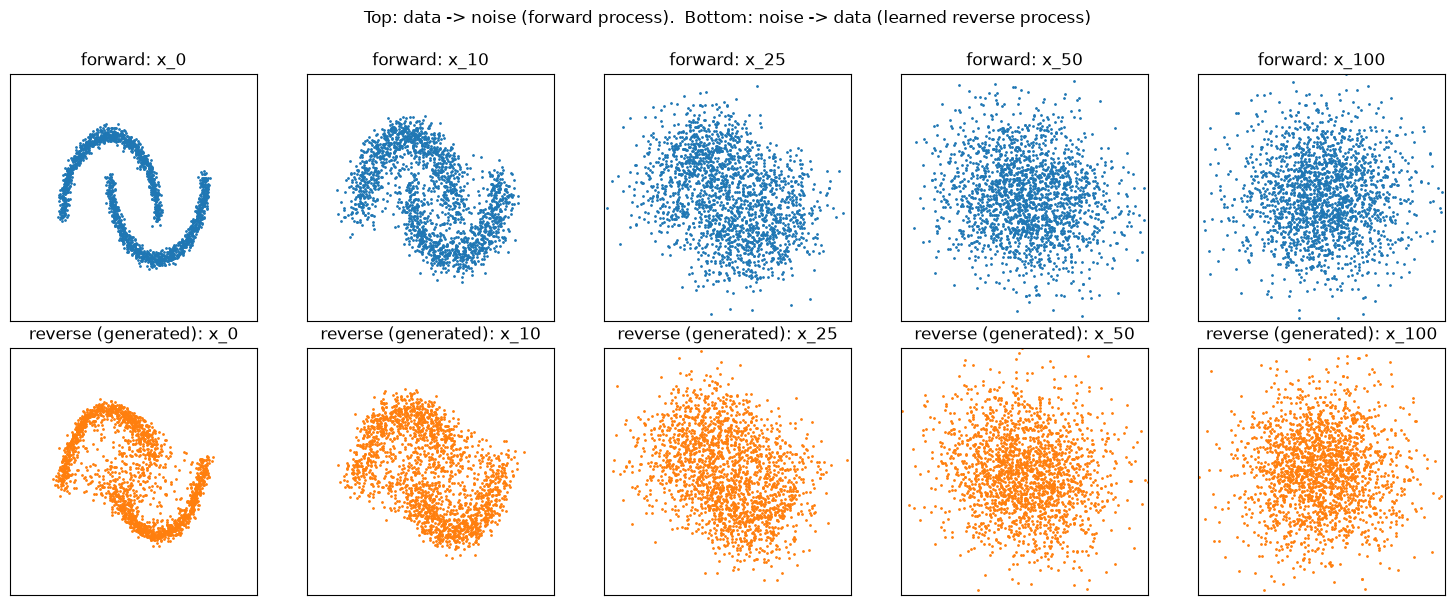

In [13]:
class EpsMLP(nn.Module):
    # epsilon-prediction network: input [x_t, time embedding (, class embedding)] -> predicted noise
    def __init__(self, dim, hidden=128, n_layers=3, n_classes=None):
        super().__init__()
        self.cls = nn.Embedding(n_classes + 1, 32) if n_classes else None     # +1 = the "no label" token
        layers, d_in = [], dim + 32 + (32 if n_classes else 0)
        for _ in range(n_layers):
            layers += [nn.Linear(d_in, hidden), nn.SiLU()]; d_in = hidden
        self.net = nn.Sequential(*layers, nn.Linear(hidden, dim))

    def forward(self, x, t, c=None):
        parts = [x, time_embedding(t)]
        if self.cls is not None:
            parts.append(self.cls(c))
        return self.net(torch.cat(parts, -1))


def train_ddpm(model, data, sch, steps, batch=256, lr=2e-3, labels=None, p_uncond=0.15, seed=SEED):
    seed_all(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    lr_sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, steps)
    losses = []
    for it in range(steps):
        idx = torch.randint(0, len(data), (batch,))
        x0 = data[idx]
        t = torch.randint(0, sch["T"], (batch,))
        eps = torch.randn_like(x0)
        c = None
        if labels is not None:
            c = labels[idx].clone()
            c[torch.rand(batch) < p_uncond] = model.cls.num_embeddings - 1    # drop the label with probability p_uncond (for CFG)
        loss = F.mse_loss(model(q_sample(x0, t, eps, sch), t, c), eps)
        opt.zero_grad(); loss.backward(); opt.step(); lr_sched.step()
        losses.append(loss.item())
    return losses


@torch.no_grad()
def ddpm_sample(model, sch, n, dim, c=None, guidance=0.0, return_path=False, seed=0):
    g = torch.Generator().manual_seed(seed)
    x = torch.randn(n, dim, generator=g)
    path = [x]
    null = None if c is None else torch.full_like(c, model.cls.num_embeddings - 1)
    for t in reversed(range(sch["T"])):
        tt = torch.full((n,), t)
        eps = model(x, tt, c)
        if c is not None and guidance:
            eps = (1 + guidance) * eps - guidance * model(x, tt, null)     # classifier-free guidance
        x = (x - sch["betas"][t] / (1 - sch["abar"][t]).sqrt() * eps) / sch["alphas"][t].sqrt()
        if t > 0:
            x = x + sch["post_var"][t].sqrt() * torch.randn(n, dim, generator=g)
        path.append(x)
    return (x, path) if return_path else x


moons_np, _ = make_moons(n_samples=4000, noise=0.05, random_state=SEED)
moons = torch.tensor((moons_np - moons_np.mean(0)) / moons_np.std(0), dtype=torch.float32)   # standardise
sch2d = make_schedule(T=100, beta_start=1e-4, beta_end=0.1)
print(f"2-D schedule: alpha-bar_T = {sch2d['abar'][-1]:.4f} (close to 0 -> x_T is almost pure noise)")
eps2d = EpsMLP(2, hidden=128)
t0 = time.perf_counter(); losses2d = train_ddpm(eps2d, moons, sch2d, steps=4000, batch=512)
print(f"trained in {time.perf_counter() - t0:.1f}s, final loss {np.mean(losses2d[-200:]):.3f}")

x_gen, path = ddpm_sample(eps2d, sch2d, 2000, 2, return_path=True)
held_out = torch.tensor((make_moons(2000, noise=0.05, random_state=9)[0] - moons_np.mean(0)) / moons_np.std(0), dtype=torch.float32)
dist_to_data = lambda x: torch.cdist(x, moons).min(1).values.mean().item()
print(f"mean distance to the nearest training point: generated {dist_to_data(x_gen):.3f}, "
      f"fresh real sample {dist_to_data(held_out):.3f}, pure noise {dist_to_data(torch.randn(2000, 2)):.3f}")
show_t = [0, 10, 25, 50, 100]
fig, ax = plt.subplots(2, 5, figsize=(15, 6))
for i, t in enumerate(show_t):
    xt = q_sample(moons[:2000], torch.full((2000,), max(t - 1, 0)), torch.randn(2000, 2), sch2d) if t > 0 else moons[:2000]
    ax[0, i].scatter(xt[:, 0], xt[:, 1], s=1); ax[0, i].set_title(f"forward: x_{t}")
    p = path[sch2d["T"] - t]
    ax[1, i].scatter(p[:, 0], p[:, 1], s=1, c="tab:orange"); ax[1, i].set_title(f"reverse (generated): x_{t}")
for a in ax.ravel():
    a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_xticks([]); a.set_yticks([]); a.set_aspect("equal")
plt.suptitle("Top: data -> noise (forward process).  Bottom: noise -> data (learned reverse process)", y=1.0)
plt.tight_layout(); plt.show()

**What just happened?** The top row melts the two moons into an isotropic Gaussian; the bottom row runs our trained network backwards from pure noise (right to left in time) and the two moons re-appear. The printed distances confirm it numerically: generated points lie far closer to the data than pure noise does, though not yet as close as a fresh real sample (some points still sit in the gap between the moons; longer training sharpens this). The network never saw a "complete" generation during training: it only learned to predict the noise in single noised examples. Composing 100 small denoising steps turns that into a generator.

### 4.2 Conditional DDPM on digits, DDIM, and classifier-free guidance

> 💬 **In plain English:** we give the noise-predictor an extra hint, "this should be a 3", and sometimes hide the hint during training, so the same network can also generate without a hint. Mixing the two predictions lets us turn up how strongly the hint is followed.

- **Conditioning:** the network also receives a class embedding $c$. During training the label is replaced by a special *null* token 20% of the time, so one network learns both $\varepsilon_\theta(x_t,t,c)$ and $\varepsilon_\theta(x_t,t,\varnothing)$.
- **Classifier-free guidance** (Ho & Salimans, 2021): at sampling time use $\tilde\varepsilon = (1+w)\,\varepsilon_\theta(x_t,t,c) - w\,\varepsilon_\theta(x_t,t,\varnothing)$. $w=0$ is ordinary conditional sampling; larger $w$ pushes samples towards "very typical members of class $c$": higher fidelity, lower diversity.
- **DDIM** (Song, Meng & Ermon, 2021): a *deterministic* sampler that skips steps. Predict $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\varepsilon)/\sqrt{\bar\alpha_t}$, then jump to an earlier time $s < t$: $x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s}\,\hat\varepsilon$. With 20 of the 200 steps it is 10× faster, using the *same* trained network.

Pixels are scaled to $[-1, 1]$; the schedule has $T=200$ steps.

digit DDPM: 181,408 parameters, trained in 17.4s, final loss 0.173


1,000 unconditional samples: DDPM 200 steps 0.9s, DDIM 20 steps 0.1s


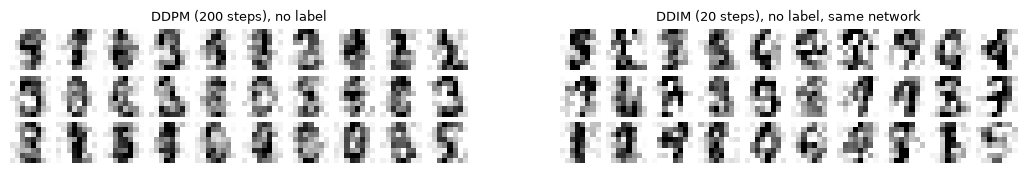

In [14]:
Xtr_pm = Xtr_t * 2 - 1                                         # [-1, 1] like most image diffusion models
sch_dig = make_schedule(T=200, beta_start=1e-4, beta_end=0.05)
eps_dig = EpsMLP(64, hidden=256, n_layers=3, n_classes=10)
t0 = time.perf_counter()
losses_dig = train_ddpm(eps_dig, Xtr_pm, sch_dig, steps=5000, batch=128, lr=1e-3, labels=ytr_t, p_uncond=0.2)
print(f"digit DDPM: {sum(p.numel() for p in eps_dig.parameters()):,} parameters, trained in {time.perf_counter() - t0:.1f}s, "
      f"final loss {np.mean(losses_dig[-200:]):.3f}")


@torch.no_grad()
def ddim_sample(model, sch, n, dim, c=None, guidance=0.0, n_steps=20, seed=0):
    g = torch.Generator().manual_seed(seed)
    times = torch.linspace(sch["T"] - 1, 0, n_steps).round().long().tolist()
    x = torch.randn(n, dim, generator=g)
    null = None if c is None else torch.full_like(c, model.cls.num_embeddings - 1)
    for i, t in enumerate(times):
        tt = torch.full((n,), t)
        eps = model(x, tt, c)
        if c is not None and guidance:
            eps = (1 + guidance) * eps - guidance * model(x, tt, null)
        ab_t = sch["abar"][t]
        x0_hat = (x - (1 - ab_t).sqrt() * eps) / ab_t.sqrt()        # predicted clean image
        ab_s = sch["abar"][times[i + 1]] if i + 1 < len(times) else torch.tensor(1.0)
        x = ab_s.sqrt() * x0_hat + (1 - ab_s).sqrt() * eps            # deterministic jump (eta = 0)
    return x

to01 = lambda x: ((x.clamp(-1, 1) + 1) / 2)
labels = torch.arange(10).repeat(10)                           # 10 of each class, column = class
null_labels = torch.full((1000,), 10)
t0 = time.perf_counter(); ddpm_samples = to01(ddpm_sample(eps_dig, sch_dig, 1000, 64, c=null_labels)); t_ddpm = time.perf_counter() - t0
t0 = time.perf_counter(); ddim_samples = to01(ddim_sample(eps_dig, sch_dig, 1000, 64, c=null_labels)); t_ddim = time.perf_counter() - t0
print(f"1,000 unconditional samples: DDPM 200 steps {t_ddpm:.1f}s, DDIM 20 steps {t_ddim:.1f}s")
fig, ax = plt.subplots(1, 2, figsize=(13, 2.6))
show_grid(ddpm_samples[:30], title="DDPM (200 steps), no label", ax=ax[0])
show_grid(ddim_samples[:30], title="DDIM (20 steps), no label, same network", ax=ax[1]); plt.show()

judge accuracy on real test digits: 0.9694444537162781


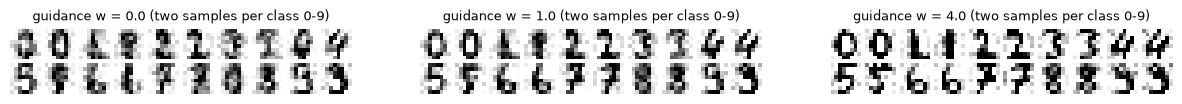

         judge agrees with requested class  within-class diversity
w = 0.0                              0.830                   2.244
w = 1.0                              0.993                   1.948
w = 4.0                              0.997                   1.992


In [15]:
# A small, separately trained classifier tells us whether a sample "looks like" the requested class
seed_all()
judge = nn.Sequential(nn.Linear(64, 128), nn.ReLU(), nn.Linear(128, 32), nn.ReLU(), nn.Linear(32, 10))
opt = torch.optim.Adam(judge.parameters(), lr=3e-3)
for epoch in range(60):
    perm = torch.randperm(len(Xtr_t))
    for i in range(0, len(perm), 64):
        b = perm[i:i + 64]
        loss = F.cross_entropy(judge(Xtr_t[b]), ytr_t[b]); opt.zero_grad(); loss.backward(); opt.step()
judge.eval()
with torch.no_grad():
    print("judge accuracy on real test digits:", (judge(Xte_t).argmax(1) == yte_t).float().mean().item())

def diversity(x):                                              # mean pairwise distance within each class
    return np.mean([torch.pdist(x[labels_cfg == k]).mean().item() for k in range(10)])

labels_cfg = torch.arange(10).repeat(30)
cfg_rows = {}
fig, ax = plt.subplots(1, 3, figsize=(15, 2.0))
for a, w in zip(ax, [0.0, 1.0, 4.0]):
    s = to01(ddim_sample(eps_dig, sch_dig, len(labels_cfg), 64, c=labels_cfg, guidance=w, n_steps=50, seed=1))
    with torch.no_grad():
        hit = (judge(s).argmax(1) == labels_cfg).float().mean().item()
    cfg_rows[f"w = {w}"] = {"judge agrees with requested class": hit, "within-class diversity": diversity(s)}
    order = torch.cat([torch.where(labels_cfg == k)[0][:2] for k in range(10)])
    show_grid(s[order], ncol=10, title=f"guidance w = {w} (two samples per class 0-9)", ax=a)
plt.show()
print(pd.DataFrame(cfg_rows).T)

**What just happened?**

- The same 200-step network produces digits with the full DDPM sampler and with **DDIM in 20 steps**, about 10× faster, without retraining: the sampler is a separate design choice from the trained noise predictor. With this small, briefly trained network the deterministic DDIM samples even look *cleaner*: the ancestral sampler injects fresh noise at every step, and the network does not remove all of it.
- With **classifier-free guidance**, the share of samples that our independent "judge" classifier assigns to the requested class rises from roughly 80-85% at $w=0$ to essentially 100% at $w=1$ and $w=4$, and the digits become bolder and more stereotyped. The within-class diversity (average pixel distance between samples of the same class) drops from $w=0$ to $w=1$; at $w=4$ it rises a little again, because the over-saturated, high-contrast strokes increase pixel distances even though the shapes are more uniform: a reminder that simple diversity metrics can mislead. Text-to-image systems use moderate guidance scales for this reason; very large scales give over-saturated, stereotyped images.

> 🎓 **Exam / interview tip:** why predict the noise $\varepsilon$ rather than $x_0$? The two are equivalent given $x_t$ (one determines the other), but the $\varepsilon$-target has unit variance at every $t$, which makes one network easy to train across all noise levels; predicting $\varepsilon$ is also equivalent to estimating the **score** $\nabla_x\log p_t(x) = -\varepsilon/\sqrt{1-\bar\alpha_t}$ (the link to score-based models).

## 5. A normalizing flow: RealNVP on 2-D data

> 💬 **In plain English:** a flow is an invertible function that warps a simple Gaussian blob into the shape of the data. Because it is invertible, we can compute the exact probability of any point by un-warping it and measuring how much the space was stretched.

**Change of variables.** If $x = f(z)$ with $f$ invertible and $z\sim p_Z$, then

$$\log p_X(x) = \log p_Z\big(f^{-1}(x)\big) + \log\left|\det\frac{\partial f^{-1}(x)}{\partial x}\right|.$$

**Affine coupling layer** (Dinh, Sohl-Dickstein & Bengio, 2017). Split $x = (x_a, x_b)$; keep $x_a$ and transform $x_b$ with a scale and shift computed from $x_a$:

$$y_a = x_a,\qquad y_b = x_b\odot\exp(s(x_a)) + t(x_a).$$

The Jacobian is triangular, so $\log|\det| = \sum s(x_a)$: cheap. The inverse is just as cheap: $x_b = (y_b - t(y_a))\odot\exp(-s(y_a))$. $s$ and $t$ can be arbitrary networks (they never need to be inverted). Alternating which half is transformed lets every coordinate be changed.

In [16]:
class Coupling(nn.Module):
    def __init__(self, flip, hidden=64):
        super().__init__()
        self.flip = flip                                                     # which coordinate is transformed
        self.net = nn.Sequential(nn.Linear(1, hidden), nn.ReLU(), nn.Linear(hidden, hidden), nn.ReLU(), nn.Linear(hidden, 2))

    def _split(self, x):
        return (x[:, 1:], x[:, :1]) if self.flip else (x[:, :1], x[:, 1:])  # (kept, transformed)

    def _join(self, a, b):
        return torch.cat([b, a], 1) if self.flip else torch.cat([a, b], 1)

    def inverse(self, x):                                                    # data -> latent direction, with log|det|
        a, b = self._split(x)
        s, t = self.net(a).chunk(2, 1)
        s = torch.tanh(s)                                                    # bounded log-scale for stability
        return self._join(a, (b - t) * torch.exp(-s)), -s.sum(1)

    def forward(self, z):                                                    # latent -> data direction
        a, b = self._split(z)
        s, t = self.net(a).chunk(2, 1)
        s = torch.tanh(s)
        return self._join(a, b * torch.exp(s) + t)


class RealNVP(nn.Module):
    def __init__(self, n_layers=8):
        super().__init__()
        self.layers = nn.ModuleList([Coupling(flip=i % 2 == 1) for i in range(n_layers)])
        self.base = torch.distributions.Normal(0.0, 1.0)

    def log_prob(self, x):                                                   # exact log-likelihood
        logdet = torch.zeros(len(x))
        for layer in reversed(self.layers):
            x, ld = layer.inverse(x); logdet = logdet + ld
        return self.base.log_prob(x).sum(1) + logdet

    @torch.no_grad()
    def sample(self, n):
        z = torch.randn(n, 2)
        for layer in self.layers:
            z = layer(z)
        return z

# Sanity checks: forward(inverse(x)) == x, and the log-det matches autograd's Jacobian
seed_all()
flow = RealNVP()
x = torch.randn(5, 2)
z = x
for layer in reversed(flow.layers):
    z, _ = layer.inverse(z)
x_back = z
for layer in flow.layers:
    x_back = layer(x_back)
print("max |f(f^-1(x)) - x| =", (x_back - x).abs().max().item())
def finv(v):
    for layer in reversed(flow.layers):
        v, _ = layer.inverse(v)
    return v
J = torch.autograd.functional.jacobian(lambda v: finv(v[None])[0], x[0])
print("log|det J| autograd:", round(torch.linalg.slogdet(J).logabsdet.item(), 5),
      "  from coupling formula:", round((flow.log_prob(x[:1]) - flow.base.log_prob(finv(x[:1])).sum(1)).item(), 5))

max |f(f^-1(x)) - x| = 3.5762786865234375e-07
log|det J| autograd: -0.77183   from coupling formula: -0.77183


flow trained in 8.1s
test negative log-likelihood (nats per point):  RealNVP 1.235   single Gaussian 2.730


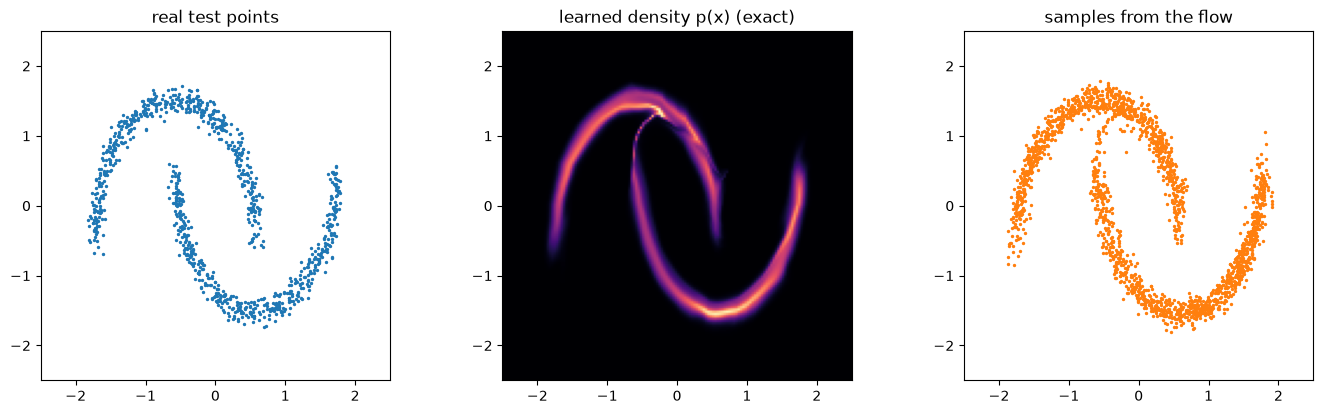

In [17]:
moons_tr, moons_te = moons[:3000], moons[3000:]
seed_all()
flow = RealNVP()
opt = torch.optim.Adam(flow.parameters(), lr=2e-3)
t0 = time.perf_counter()
for it in range(1000):
    xb = moons_tr[torch.randint(0, len(moons_tr), (256,))]
    loss = -flow.log_prob(xb).mean()                                         # maximum likelihood, exactly
    opt.zero_grad(); loss.backward(); opt.step()
print(f"flow trained in {time.perf_counter() - t0:.1f}s")

with torch.no_grad():
    nll_flow = -flow.log_prob(moons_te).mean().item()
mu, cov = moons_tr.mean(0), torch.cov(moons_tr.T)
nll_gauss = -torch.distributions.MultivariateNormal(mu, cov).log_prob(moons_te).mean().item()
print(f"test negative log-likelihood (nats per point):  RealNVP {nll_flow:.3f}   single Gaussian {nll_gauss:.3f}")

g1, g2 = torch.meshgrid(torch.linspace(-2.5, 2.5, 150), torch.linspace(-2.5, 2.5, 150), indexing="xy")
with torch.no_grad():
    dens = flow.log_prob(torch.stack([g1.ravel(), g2.ravel()], 1)).exp().view(150, 150)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
ax[0].scatter(moons_te[:, 0], moons_te[:, 1], s=2); ax[0].set_title("real test points")
ax[1].imshow(dens.numpy(), origin="lower", extent=[-2.5, 2.5, -2.5, 2.5], cmap="magma"); ax[1].set_title("learned density p(x) (exact)")
fs = flow.sample(2000); ax[2].scatter(fs[:, 0], fs[:, 1], s=2, c="tab:orange"); ax[2].set_title("samples from the flow")
for a in ax: a.set_xlim(-2.5, 2.5); a.set_ylim(-2.5, 2.5); a.set_aspect("equal")
plt.tight_layout(); plt.show()

**What just happened?** The coupling layers are exactly invertible (round-trip error at float precision) and their cheap log-determinant formula agrees with the log-determinant of the full Jacobian computed by autograd. Trained by plain maximum likelihood, the flow assigns the held-out moons a much higher likelihood (lower NLL, in nats per point) than the best single Gaussian, and we can draw its density exactly. The thin "bridges" between the two moons in the density and samples are typical: a flow is a continuous, invertible warp of a single blob, so it struggles to put *exactly zero* density between separate pieces.

> 🎓 **Exam / interview tip:** flows give **exact** likelihoods and exact latent codes, at the price of architectural constraints (invertibility, same dimension in and out). VAEs give a **bound** on the likelihood; GANs give **none**; diffusion models give a variational bound, and with the probability-flow ODE also an exact (but expensive) likelihood.

## 6. Evaluating generative models

> 💬 **In plain English:** there is no single "accuracy" for a generator. We ask: are the samples realistic (quality)? do they cover all kinds of real data (diversity)? are they new, or copies of training examples (memorisation)? and, if the model allows, how probable does it find real data (likelihood)?

| Metric | Measures | Needs |
|---|---|---|
| **Log-likelihood** / ELBO / bits-per-dim | how much probability the model gives to held-out data | a likelihood (flows exactly; VAE bound; not GANs) |
| **FID** (Heusel et al., 2017) | Fréchet distance between Gaussians fitted to *features* of real and generated samples: $\lVert\mu_r-\mu_g\rVert^2 + \operatorname{Tr}(\Sigma_r+\Sigma_g-2(\Sigma_r\Sigma_g)^{1/2})$ | a feature network (Inception-v3 for real FID) |
| **Precision / recall for distributions** (Kynkäänniemi et al., 2019) | precision: share of fakes that land inside the real-data manifold; recall: share of real data covered by the fake manifold (manifold = union of $k$-NN balls) | features |
| **Memorisation check** | distance from each sample to its nearest *training* example vs typical test-to-train distances | the training set |

Real FID uses Inception-v3 features of 299×299 images; that would need a large download. We use a **small proxy**: the 32-dimensional hidden layer of the "judge" classifier trained in Section 4.2, so our numbers are only comparable *within this notebook*.

In [18]:
from scipy import linalg

@torch.no_grad()
def features(x):
    return judge[:4](torch.as_tensor(x, dtype=torch.float32)).numpy()        # 32-d penultimate activations

def frechet_distance(fa, fb):
    mu_a, mu_b = fa.mean(0), fb.mean(0)
    eye = 1e-6 * np.eye(fa.shape[1])                                             # tiny ridge: ReLU features can make covariances singular
    ca, cb = np.cov(fa, rowvar=False) + eye, np.cov(fb, rowvar=False) + eye
    covmean = linalg.sqrtm(ca @ cb).real                                         # matrix square root
    return float(((mu_a - mu_b) ** 2).sum() + np.trace(ca + cb - 2 * covmean))

def precision_recall(real_f, fake_f, k=3):
    def radii(f):                                            # distance to the k-th nearest neighbour within the set
        d = torch.cdist(torch.tensor(f), torch.tensor(f))
        return d.kthvalue(k + 1, dim=1).values               # +1 skips the point itself
    r_real, r_fake = radii(real_f), radii(fake_f)
    d = torch.cdist(torch.tensor(fake_f), torch.tensor(real_f))                 # (n_fake, n_real)
    precision = (d <= r_real[None, :]).any(1).float().mean().item()              # fake inside some real ball
    recall = (d.T <= r_fake[None, :]).any(1).float().mean().item()               # real inside some fake ball
    return precision, recall

seed_all(5)
with torch.no_grad():
    vae_samples = torch.sigmoid(vae.dec(torch.randn(1000, 2)))
    vae8_samples = torch.sigmoid(beta_models[1.0].dec(torch.randn(1000, 8)))
candidates = {
    "real test digits (reference)": Xte_t,
    "VAE, 2-D latent": vae_samples,
    "VAE, 8-D latent": vae8_samples,
    "DCGAN": dcgan_samples,
    "DDPM 200 steps (no label)": ddpm_samples,
    "DDIM 20 steps (no label)": ddim_samples,
    "uniform noise (sanity check)": torch.rand(1000, 64),
}
real_feat = features(Xtr_t)
rows = {}
for name, s in candidates.items():
    f = features(s)
    p, r = precision_recall(real_feat, f)
    rows[name] = {"FD (judge features)": frechet_distance(real_feat, f), "precision": p, "recall": r}
eval_table = pd.DataFrame(rows).T
print(eval_table)

                              FD (judge features)  precision  recall
real test digits (reference)                1.070      0.900   0.930
VAE, 2-D latent                            40.692      0.869   0.038
VAE, 8-D latent                            25.801      0.778   0.360
DCGAN                                      19.061      0.445   0.607
DDPM 200 steps (no label)                  37.279      0.562   0.683
DDIM 20 steps (no label)                   19.210      0.493   0.839
uniform noise (sanity check)              349.517      0.222   0.132


**What just happened?** Real test digits score the best Fréchet distance (about 1) with precision 0.90 and recall 0.93; that row is the yardstick (it is not exactly zero because the test set is a different, smaller sample). Uniform noise is terrible on every metric, as a sanity check should be. Between those extremes the generators separate along the two axes the metrics were designed for:

- The **2-D VAE** has high precision (0.87) but almost no recall (0.04): its blurry "average" digits sit inside the real-data region of feature space but cover only a sliver of the variety. The 8-D VAE covers more (recall 0.36).
- The **DCGAN** has a better Fréchet distance and much higher recall, but under half of its samples fall inside the real manifold (precision 0.45): varied, but often malformed.
- **Diffusion** gives the best coverage: DDIM reaches a recall of about 0.84 with a Fréchet distance on par with the DCGAN, while the noisier 200-step ancestral samples score worse on Fréchet distance.

No model wins on every column, and with models this small the ranking could change with more training. The single Fréchet number mixes quality and coverage, which is why papers report precision and recall alongside FID.

### 6.1 Did the models just memorise the training set?

For every generated sample we find the nearest training image (pixel space). If a generator copies training data, these distances will be much **smaller** than the distances from genuinely new digits (the test set) to their nearest training image.

                              median NN distance  \
VAE, 8-D latent                            1.219   
DCGAN                                      1.603   
DDPM 200 steps (no label)                  1.545   
real test digits (reference)               1.048   

                              share closer than 1st pct of test  
VAE, 8-D latent                                           0.002  
DCGAN                                                     0.000  
DDPM 200 steps (no label)                                 0.000  
real test digits (reference)                              0.010  


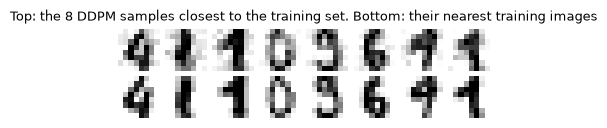

In [19]:
def nn_dist(x, ref=Xtr_t):
    return torch.cdist(torch.as_tensor(x, dtype=torch.float32), ref).min(1)

base = nn_dist(Xte_t).values
mem_rows = {}
for name in ["VAE, 8-D latent", "DCGAN", "DDPM 200 steps (no label)"]:
    d = nn_dist(candidates[name]).values
    mem_rows[name] = {"median NN distance": d.median().item(), "share closer than 1st pct of test": (d < base.quantile(0.01)).float().mean().item()}
mem_rows["real test digits (reference)"] = {"median NN distance": base.median().item(), "share closer than 1st pct of test": 0.01}
print(pd.DataFrame(mem_rows).T)

d = nn_dist(candidates["DDPM 200 steps (no label)"])
closest = d.values.argsort()[:8]
pairs = torch.cat([candidates["DDPM 200 steps (no label)"][closest], Xtr_t[d.indices[closest]]])
show_grid(pairs, ncol=8, title="Top: the 8 DDPM samples closest to the training set. Bottom: their nearest training images"); plt.show()

**What just happened?** Generated samples are, if anything, *farther* from their nearest training image than real unseen test digits are (median distances of about 1.2-1.6 vs about 1.05), and essentially none is closer than the 1st percentile of test-to-train distances. Even the closest pairs are similar digits rather than pixel copies, so these small models are generating rather than retrieving. This check matters in practice: large diffusion models have been shown to reproduce some heavily duplicated training images (Carlini et al., 2023), which raises privacy and copyright issues.

> ⚠️ **Common mistake:** reporting FID on a few hundred samples. The Fréchet distance is **biased** upwards for small sample sizes, so numbers computed with different sample counts are not comparable. Papers use 10k-50k samples with Inception features.

## 7. Comparison table

> 💬 **In plain English:** every family wins on something different; modern systems often combine them.

| | VAE | GAN | Normalizing flow | Diffusion |
|---|---|---|---|---|
| Sample quality | blurry (Gaussian likelihood averages) | **sharp** | moderate | **sharp, state of the art** |
| Diversity / mode coverage | good | risk of **mode collapse** | good | **good** |
| Sampling speed | **1 network pass** | **1 pass** | **1 pass** | slow: tens to hundreds of passes (DDIM, distillation, consistency models reduce this) |
| Likelihood | lower bound (ELBO) | none | **exact** | bound (exact via ODE, expensive) |
| Latent space | low-dimensional, meaningful | low-dimensional, no encoder | same dimension as data, exact inverse | same dimension as data (DDIM gives an invertible map) |
| Training stability | **stable** | fragile (two-player game) | stable | **stable** (simple regression loss) |
| Typical use today | the compressor inside latent diffusion; representation learning | real-time image synthesis, super-resolution, as an extra loss in VAE/diffusion decoders | density estimation, simulation-based inference, components in other models | text-to-image, video, audio; flow-matching variants |

## 8. How this connects to modern AI

> 💬 **In plain English:** today's image, video and audio generators are built from exactly these parts, scaled up and combined.

| What you built | Where it lives in modern AI |
|---|---|
| VAE encoder/decoder | **Latent diffusion** (Stable Diffusion) first compresses images with a VAE-style autoencoder and runs diffusion in its latent space |
| ε-prediction + noise schedule | the training objective of essentially all image, video and audio diffusion models |
| DDIM | the basis of fast deterministic samplers; DDIM inversion is used for image editing |
| Classifier-free guidance | the "guidance scale" slider in text-to-image tools |
| Non-saturating GAN loss / adversarial training | still used as an extra loss to sharpen VAE decoders and in fast distilled generators |
| Coupling layers, change of variables | flows; the same change-of-variables idea underlies **flow matching** / rectified flow, used by recent text-to-image models |
| Precision/recall, FID, memorisation checks | how generative models are benchmarked and audited for training-data leakage |

Related notebooks: [`06_Computer_Vision/06_image_generation.ipynb`](../06_Computer_Vision/06_image_generation.ipynb) (the modern image-generation landscape), [`09_self_supervised_learning.ipynb`](09_self_supervised_learning.ipynb) (representation learning), [`00_AI_Fundamentals/04_privacy_and_security.ipynb`](../00_AI_Fundamentals/04_privacy_and_security.ipynb) (training-data leakage).

## 9. Recap

- **AE vs VAE:** a VAE maximises the ELBO = reconstruction − KL; the KL keeps codes near $\mathcal N(0,I)$ so prior samples decode well. The reparameterisation trick $z=\mu+\sigma\varepsilon$ makes it trainable. **β** trades reconstruction for a simpler latent space; too much β causes posterior collapse.
- **GANs:** a minimax game whose optimum matches the data distribution; use the **non-saturating** generator loss; watch **mode coverage**, not losses. **WGAN-GP** uses a critic with a gradient penalty; **DCGAN** uses (transposed) convolutions with BatchNorm.
- **DDPM:** fixed forward noising with closed form $x_t=\sqrt{\bar\alpha_t}x_0+\sqrt{1-\bar\alpha_t}\varepsilon$; train an ε-predictor with MSE; sample by iterated denoising. **DDIM** samples deterministically in far fewer steps; **classifier-free guidance** mixes conditional and unconditional predictions to trade diversity for fidelity.
- **Flows:** invertible coupling layers with a triangular Jacobian give **exact** log-likelihoods.
- **Evaluation:** likelihood where available, Fréchet distance in a feature space, **precision** (quality) and **recall** (coverage), and a nearest-neighbour **memorisation** check.

## Practice problems

**1. (Easy, calculation)** Compute $\mathrm{KL}(\mathcal N(\mu,\sigma^2)\,\Vert\,\mathcal N(0,1))$ for the 2-D diagonal Gaussian with $\mu = (1, -0.5)$, $\sigma = (0.5, 2)$ by hand and with code.

<details><summary>Show solution</summary>

Per dimension $\tfrac12(\mu^2+\sigma^2-1-\ln\sigma^2)$: first $\tfrac12(1 + 0.25 - 1 + 1.386) = 0.818$; second $\tfrac12(0.25 + 4 - 1 - 1.386) = 0.932$. Total $1.750$ nats.

```python
import torch, math

def kl_diag_gauss(mu, sigma):
    # KL( N(mu, sigma^2) || N(0, 1) ), summed over dimensions
    return 0.5 * (mu ** 2 + sigma ** 2 - 1 - torch.log(sigma ** 2)).sum()

mu, sigma = torch.tensor([1.0, -0.5]), torch.tensor([0.5, 2.0])
ours = kl_diag_gauss(mu, sigma)
ref = torch.distributions.kl_divergence(torch.distributions.Normal(mu, sigma), torch.distributions.Normal(0.0, 1.0)).sum()
print(round(ours.item(), 4), round(ref.item(), 4))
assert torch.allclose(ours, ref)
```
</details>

**2. (Easy, conceptual)** Why can't you train a VAE by back-propagating through `torch.normal(mu, sigma)` directly, and what does the reparameterisation trick change?

<details><summary>Show solution</summary>

A sample drawn by a random-number generator is not a differentiable function of $\mu$ and $\sigma$ (autograd sees a constant). Writing $z=\mu+\sigma\varepsilon$ with $\varepsilon\sim\mathcal N(0,I)$ drawn independently makes $z$ a deterministic, differentiable function of $(\mu,\sigma)$ given $\varepsilon$, so $\partial z/\partial\mu = 1$ and $\partial z/\partial\sigma = \varepsilon$. (The alternative, the score-function/REINFORCE estimator, is unbiased but has much higher variance; see problem 3.)
</details>

**3. (Medium, coding)** Estimate $\frac{d}{d\mu}\mathbb E_{z\sim\mathcal N(\mu,1)}[z^2]$ at $\mu=1.5$ (true value 3) with the reparameterisation estimator and with the score-function estimator, and compare their variances.

<details><summary>Show solution</summary>

```python
import torch

# Goal: d/dmu E_{z ~ N(mu, 1)}[z^2] at mu = 1.5. True value: E[z^2] = mu^2 + 1, derivative 2 mu = 3.
torch.manual_seed(0)
mu, n, reps = 1.5, 100, 500
reparam, score = [], []
for _ in range(reps):
    eps = torch.randn(n)
    z = mu + eps                                   # reparameterised sample
    reparam.append((2 * z).mean().item())          # d/dmu (mu + eps)^2 = 2 z
    score.append((z ** 2 * (z - mu)).mean().item())  # REINFORCE: f(z) * d/dmu log N(z; mu, 1)
reparam, score = torch.tensor(reparam), torch.tensor(score)
print(f"reparameterisation: mean {reparam.mean():.3f}, std {reparam.std():.3f}")
print(f"score function     : mean {score.mean():.3f}, std {score.std():.3f}")
assert abs(reparam.mean() - 3) < 0.05 and abs(score.mean() - 3) < 0.3 and score.std() > 3 * reparam.std()
```
Both estimators are unbiased, but the score-function estimator's standard deviation is several times larger. This is why VAEs use reparameterisation, while RL policy gradients (where actions are discrete and the reward is not differentiable) must use the score-function estimator plus variance-reduction tricks.
</details>

**4. (Medium, conceptual)** A GAN's generator loss keeps falling while its samples all look like the digit 1. What is happening, how would you detect it automatically, and name two remedies.

<details><summary>Show solution</summary>

**Mode collapse**: the generator found a few outputs that fool the current discriminator and stopped covering the rest of the distribution. Detect it with diversity/coverage metrics: low **recall** in precision/recall, low class entropy of a classifier's predictions on samples, or mode counts (as in Section 3.1). Remedies: Wasserstein loss with gradient penalty, minibatch discrimination / minibatch standard-deviation features, spectral normalisation, unrolled GANs, or switching to a likelihood-based or diffusion model.
</details>

**5. (Medium, coding)** Verify for a 4-D affine coupling layer that the log-determinant formula $\sum s(x_a)$ equals the log-determinant of the full Jacobian computed by autograd.

<details><summary>Show solution</summary>

```python
import torch, torch.nn as nn

torch.manual_seed(0)
net = nn.Sequential(nn.Linear(2, 16), nn.Tanh(), nn.Linear(16, 4))    # s(x_a), t(x_a) for a 4-D input split 2 + 2

def coupling(x):                                   # y_a = x_a, y_b = x_b * exp(s) + t
    xa, xb = x[:2], x[2:]
    s, t = net(xa).chunk(2)
    return torch.cat([xa, xb * torch.exp(s) + t]), s.sum()

x = torch.randn(4)
y, logdet_formula = coupling(x)
J = torch.autograd.functional.jacobian(lambda v: coupling(v)[0], x)
logdet_autograd = torch.logdet(J)
print(J.round(decimals=3)); print(logdet_formula.item(), logdet_autograd.item())
assert torch.allclose(logdet_formula, logdet_autograd, atol=1e-5)
```
The Jacobian is block lower-triangular: identity for $x_a$, $\operatorname{diag}(e^{s})$ for $x_b$, and an arbitrary block below the diagonal (it does not affect the determinant).
</details>

**6. (Medium, derivation)** Show that in classifier-free guidance, $\tilde\varepsilon = (1+w)\varepsilon(x,c) - w\,\varepsilon(x,\varnothing)$ corresponds to sampling from a distribution proportional to $p(x\mid c)\,p(c\mid x)^w$.

<details><summary>Show solution</summary>

Noise predictions are scaled scores: $\varepsilon(x_t, c) = -\sqrt{1-\bar\alpha_t}\,\nabla\log p_t(x_t\mid c)$ and $\varepsilon(x_t,\varnothing) = -\sqrt{1-\bar\alpha_t}\,\nabla\log p_t(x_t)$. So $\tilde\varepsilon \propto -[(1+w)\nabla\log p(x\mid c) - w\nabla\log p(x)] = -[\nabla\log p(x\mid c) + w(\nabla\log p(x\mid c)-\nabla\log p(x))]$. By Bayes, $\nabla\log p(x\mid c) - \nabla\log p(x) = \nabla\log p(c\mid x)$, so the guided score is $\nabla\log[p(x\mid c)\,p(c\mid x)^w]$: an implicit classifier $p(c\mid x)$ raised to the power $w$ sharpens samples towards the class.
</details>

**7. (Hard, conceptual)** DDIM with $\eta = 0$ is deterministic. Explain why this makes it possible to *invert* a real image into a noise vector, and give one application.

<details><summary>Show solution</summary>

Each DDIM step is a deterministic function $x_s = \sqrt{\bar\alpha_s}\hat x_0(x_t) + \sqrt{1-\bar\alpha_s}\hat\varepsilon(x_t)$; it is a discretisation of the probability-flow ODE, which is invertible. Running the update in the opposite direction ($t$ increasing, from $x_0$ to $x_T$) approximately recovers the noise that would generate the image. Applications: image editing (invert, change the prompt or guidance, regenerate: e.g. prompt-to-prompt, null-text inversion), interpolation between real images in noise space, and likelihood computation via the ODE.
</details>

## Further reading

- Goodfellow, Bengio & Courville, *Deep Learning* (2016), Ch. 20 "Deep Generative Models" (free at deeplearningbook.org); Kevin Murphy, *Probabilistic Machine Learning: Advanced Topics* (2023, free PDF), chapters on VAEs, GANs, flows and diffusion.
- Kingma & Welling (2014) "Auto-Encoding Variational Bayes"; Higgins et al. (2017) β-VAE; Goodfellow et al. (2014) GANs; Radford et al. (2016) DCGAN; Gulrajani et al. (2017) WGAN-GP; Dinh et al. (2017) RealNVP; Ho et al. (2020) DDPM; Song et al. (2021) DDIM; Ho & Salimans (2021) classifier-free guidance; Kynkäänniemi et al. (2019) improved precision and recall; Heusel et al. (2017) FID.
- Lilian Weng, "What are Diffusion Models?" (blog, 2021) and "Flow-based Deep Generative Models" (blog, 2018).

## Next notebook

Continue with [`21_graph_machine_learning_hands_on.ipynb`](21_graph_machine_learning_hands_on.ipynb): node embeddings, spectral methods, GCN/GraphSAGE/GAT from scratch and link prediction.